# Memorize one Russian passage

Run all cells with the project environment. This trains a fresh model on one passage; the evaluation corpus is deliberately identical to training. Outputs go to a new `artifacts/pretraining/memorization-*` directory.


In [1]:
from dataclasses import asdict
from datetime import datetime
import json
from pathlib import Path
import time

import matplotlib.pyplot as plt
import mlx.core as mx
import numpy as np
from tokenizers import Tokenizer

from llm_training.models.gpt_mlx import GPT
from llm_training.models.config import GPTConfig
from llm_training.pretraining_mlx.data import encode_documents
from llm_training.pretraining_mlx.train import TrainConfig, train
from llm_training.pretraining_mlx.checkpoint import CheckpointConfig, CheckpointWriter
from llm_training.pretraining_mlx.generate import load_checkpoint, generate_text

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
run_dir = root / 'artifacts/pretraining' / datetime.now().strftime('memorization-%Y%m%d-%H%M%S-%f')
run_dir.mkdir(parents=True, exist_ok=False)
tokenizer_path = root / 'artifacts/tokenization/fineweb2-rus-bpe-8k-02/tokenizer.json'
tokenizer = Tokenizer.from_file(str(tokenizer_path))
tokenizer.save(str(run_dir / 'tokenizer.json'))
mx.set_default_device(mx.gpu)
mx.random.seed(42)

In [2]:
text = (
    'В субботу утром Анна отправилась в маленькую библиотеку возле реки. '
    'Ночью прошёл дождь, и на дорожках ещё блестели лужи. '
    'У входа её встретил библиотекарь Павел. Он поставил на стол чашку чая '
    'и показал старую карту города. На карте был отмечен сад за железнодорожным мостом. '
    'Анна решила найти этот сад и узнать, почему о нём почти никто не помнит. '
    'Она взяла блокнот, поблагодарила Павла и вышла на улицу. '
    'Дорога шла вдоль реки, мимо пекарни и красного кирпичного дома. '
    'Через полчаса Анна увидела деревянные ворота. За ними росли яблони, '
    'а возле скамейки стояла пожилая женщина с зелёной лейкой. '
    'Женщину звали Мария. Она объяснила, что раньше здесь собирались жители всего района. '
    'Теперь за садом ухаживали только несколько соседей. '
    'Анна предложила помочь им в следующее воскресенье. '
    'Мария улыбнулась и подарила ей маленькое яблоко. '
    'Вечером Анна вернулась в библиотеку и рассказала Павлу о своей прогулке. '
    'Они решили написать объявление и пригласить соседей на уборку сада.'
)
ids = tokenizer.encode(text, add_special_tokens=False).ids
assert tokenizer.decode(ids) == text
train_tokens = encode_documents([text], tokenizer, '<|endoftext|>')
assert train_tokens.size > 256
model_config = GPTConfig(vocab_size=tokenizer.get_vocab_size(), context_length=256,
                        n_layers=4, n_heads=4, d_model=128,
                        attention_backend='reference', stable_softmax=True)
# Keep current Adam betas, clipping, and peak LR. The short diagnostic has its own schedule.
training = TrainConfig(steps=1000, batch_size=4, gradient_accumulation_steps=2,
                       learning_rate=6e-4, min_learning_rate=6e-5,
                       lr_schedule='cosine', warmup_steps=20, lr_decay_steps=1000,
                       weight_decay=0.05, grad_clip=1.0, sampling='random',
                       compile_step=True, eval_every=50, eval_batches=4,
                       seed=42, device='gpu')
settings = {'data': {'source': 'inline Russian passage'},
            'tokenizer': {'eos_token': '<|endoftext|>'},
            'model': asdict(model_config), 'training': asdict(training)}
(run_dir / 'passage.txt').write_text(text + '\n', encoding='utf-8')
(run_dir / 'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
print(f'{len(ids)} passage tokens; {training.steps} updates; {training.effective_batch_size * 256} tokens/update')
print(f'Artifacts: {run_dir}')

289 passage tokens; 1000 updates; 2048 tokens/update
Artifacts: /Users/mikhail.n/Desktop/learning/learning_llm_training/artifacts/pretraining/memorization-20261118-085320-271520


In [3]:
model = GPT(model_config)
metrics = []

def record(step, train_loss, val_loss, extra):
    # val_loss here measures memorization on the SAME passage, not generalization.
    row = dict(step=step, train_loss=train_loss, memorization_loss=val_loss,
               learning_rate=extra.get('learning_rate'))
    metrics.append(row)
    with (run_dir / 'metrics.jsonl').open('a') as file:
        file.write(json.dumps(row) + '\n')
    print(f'update {step:4d}: passage loss={val_loss:.6f}', flush=True)

writer = CheckpointWriter(run_dir, model, settings, training, CheckpointConfig(every=0))
started = time.perf_counter()
train(model, train_tokens, train_tokens, training,
      record_metrics=record, record_checkpoint=writer)
elapsed = time.perf_counter() - started
print(f'Elapsed: {elapsed:.1f} seconds')

Device: Device(gpu, 0); parameters: 1,850,112
training [----------------]   0.0% 0/1000 tok/s=-- elapsed=00:00:00 ETA=--:--:--
update    0: passage loss=9.020560
update    1: passage loss=8.990152
update   50: passage loss=3.735338
update  100: passage loss=0.765360
update  150: passage loss=0.097581
update  200: passage loss=0.018812
update  250: passage loss=0.005538
update  300: passage loss=0.002325
update  350: passage loss=0.000907
update  400: passage loss=0.000382
update  450: passage loss=0.000131
update  500: passage loss=0.000051
update  550: passage loss=0.000023
update  600: passage loss=0.000009
update  650: passage loss=0.000004
update  700: passage loss=0.000002
update  750: passage loss=0.000002
update  800: passage loss=0.000001
update  850: passage loss=0.000001
update  900: passage loss=0.000001
update  950: passage loss=0.000001
update 1000: passage loss=0.000000
finished [################] 100.0% 1000/1000 tok/s=95,413 elapsed=00:00:21 ETA=00:00:00 train=0.0000 va

In [4]:
# Verify the public checkpoint loader, teacher-forced predictions, and autoregressive sampling.
loaded, saved_tokenizer, eos_id = load_checkpoint(run_dir, device='gpu')
model.eval()
probe = train_tokens[:256][None, :]
reload_error = mx.max(mx.abs(model(probe)[0] - loaded(probe)[0])).item()
assert reload_error == 0
samples = []
for offset in (0, 64, 128):
    window = ids[offset:offset + 257]
    x, y = mx.array([window[:-1]]), mx.array([window[1:]])
    logits, loss = loaded(x, y)
    accuracy = mx.mean((mx.argmax(logits, axis=-1) == y).astype(mx.float32)).item()
    prefix_length, continuation_length = 32, 64
    prefix = ids[offset:offset + prefix_length]
    expected = ids[offset + prefix_length:offset + prefix_length + continuation_length]
    prompt = saved_tokenizer.decode(prefix)
    assert saved_tokenizer.encode(prompt, add_special_tokens=False).ids == prefix
    greedy = mx.array([prefix])
    for _ in expected:
        scores, _ = loaded(greedy[:, -256:])
        next_id = mx.argmax(scores[:, -1, :], axis=-1)[:, None]
        greedy = mx.concatenate([greedy, next_id], axis=1)
        mx.eval(greedy)
    actual = greedy[0, prefix_length:].tolist()
    sampled_text = generate_text(loaded, saved_tokenizer, prompt,
                                 max_new_tokens=continuation_length, temperature=0.2,
                                 seed=42, eos_id=eos_id)
    row = dict(offset=offset, teacher_forced_loss=loss.item(), accuracy=accuracy,
               greedy_exact_match=actual == expected,
               greedy_token_accuracy=sum(a == b for a, b in zip(actual, expected)) / len(expected),
               prompt=prompt, expected=saved_tokenizer.decode(prefix + expected),
               greedy=saved_tokenizer.decode(prefix + actual), low_temperature=sampled_text)
    samples.append(row)
    print(json.dumps(row, ensure_ascii=False, indent=2))
summary = dict(passage_tokens=len(ids), updates=training.steps, elapsed_seconds=elapsed,
               initial_loss=metrics[0]['memorization_loss'],
               final_loss=metrics[-1]['memorization_loss'], reload_max_logit_error=reload_error,
               samples=samples)
summary['passed'] = (summary['final_loss'] < 0.1
                     and all(s['accuracy'] >= 0.99 and s['greedy_exact_match'] for s in samples))
(run_dir / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('MEMORIZATION PASS:', summary['passed'])

{
  "offset": 0,
  "teacher_forced_loss": 3.2866830679267878e-06,
  "accuracy": 1.0,
  "greedy_exact_match": true,
  "greedy_token_accuracy": 1.0,
  "prompt": "В субботу утром Анна отправилась в маленькую библиотеку возле реки. Ночью прошёл дождь, и на дорожках ещё",
  "expected": "В субботу утром Анна отправилась в маленькую библиотеку возле реки. Ночью прошёл дождь, и на дорожках ещё блестели лужи. У входа её встретил библиотекарь Павел. Он поставил на стол чашку чая и показал старую карту города. На карте был отмечен сад за железнодорожным мостом. Анна решила найти этот сад и узнать, почему",
  "greedy": "В субботу утром Анна отправилась в маленькую библиотеку возле реки. Ночью прошёл дождь, и на дорожках ещё блестели лужи. У входа её встретил библиотекарь Павел. Он поставил на стол чашку чая и показал старую карту города. На карте был отмечен сад за железнодорожным мостом. Анна решила найти этот сад и узнать, почему",
  "low_temperature": "В субботу утром Анна отправилась в маленьк

notebooks/07_memorization.ipynb:cell5:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


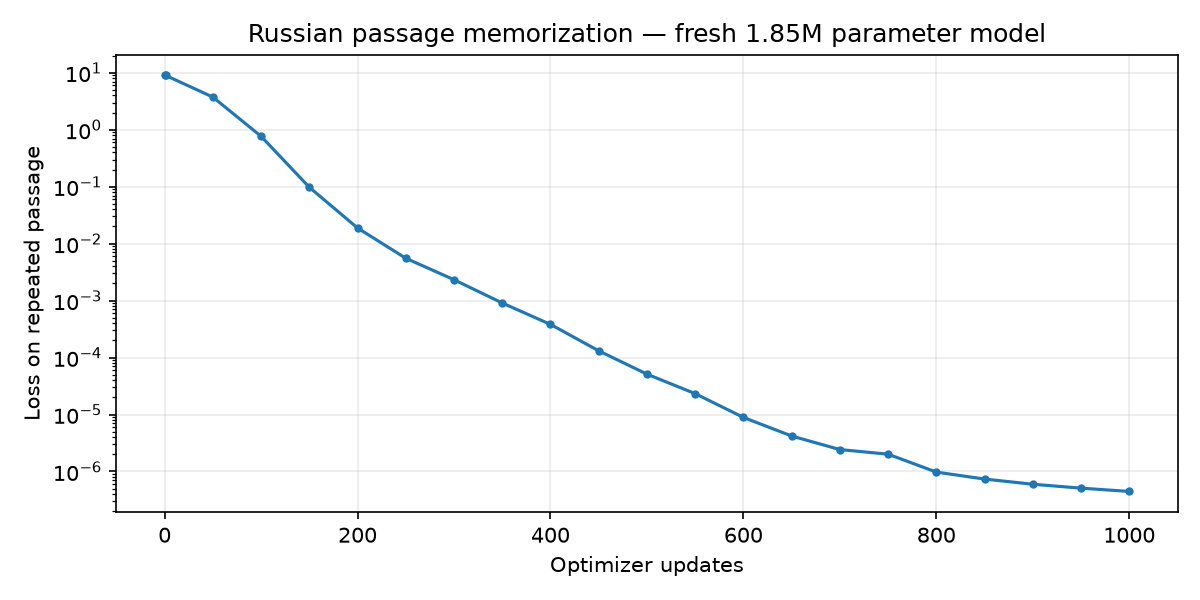

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([m['step'] for m in metrics], [m['memorization_loss'] for m in metrics], marker='.')
ax.set(xlabel='Optimizer updates', ylabel='Loss on repeated passage', yscale='log',
       title='Russian passage memorization — fresh 1.85M parameter model')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(run_dir / 'loss.png', dpi=150)
plt.show()

## Cover all prompt positions

The single copy has 290 tokens including EOS, allowing only 34 training-window starts (0–33). The middle prompts start at 64 and 128. Repeat the same passage twice so every tested start can occur in training, and train a fresh model with identical settings. Both runs are retained.


In [6]:
first_summary = summary
first_run_dir = run_dir
run_dir = root / 'artifacts/pretraining' / datetime.now().strftime('memorization-%Y%m%d-%H%M%S-%f')
run_dir.mkdir(parents=True, exist_ok=False)
tokenizer.save(str(run_dir / 'tokenizer.json'))
mx.random.seed(42)
train_tokens = encode_documents([text, text], tokenizer, '<|endoftext|>')
settings['data']['copies'] = 2
(run_dir / 'passage.txt').write_text(text + '\n', encoding='utf-8')
(run_dir / 'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
print(f'{train_tokens.size} tokens including both EOS markers; window starts 0–{train_tokens.size - 257}')
print(f'Artifacts: {run_dir}')

580 tokens including both EOS markers; window starts 0–323
Artifacts: /Users/mikhail.n/Desktop/learning/learning_llm_training/artifacts/pretraining/memorization-20261118-085459-496348


In [7]:
model = GPT(model_config)
metrics = []

def record(step, train_loss, val_loss, extra):
    # val_loss here measures memorization on the SAME passage, not generalization.
    row = dict(step=step, train_loss=train_loss, memorization_loss=val_loss,
               learning_rate=extra.get('learning_rate'))
    metrics.append(row)
    with (run_dir / 'metrics.jsonl').open('a') as file:
        file.write(json.dumps(row) + '\n')
    print(f'update {step:4d}: passage loss={val_loss:.6f}', flush=True)

writer = CheckpointWriter(run_dir, model, settings, training, CheckpointConfig(every=0))
started = time.perf_counter()
train(model, train_tokens, train_tokens, training,
      record_metrics=record, record_checkpoint=writer)
elapsed = time.perf_counter() - started
print(f'Elapsed: {elapsed:.1f} seconds')

Device: Device(gpu, 0); parameters: 1,850,112
training [----------------]   0.0% 0/1000 tok/s=-- elapsed=00:00:00 ETA=--:--:--
update    0: passage loss=9.018880
update    1: passage loss=8.989705
update   50: passage loss=3.755973
update  100: passage loss=0.898832
update  150: passage loss=0.158380
update  200: passage loss=0.031828
update  250: passage loss=0.018960
update  300: passage loss=0.011657
update  350: passage loss=0.010194
update  400: passage loss=0.005980
update  450: passage loss=0.004268
update  500: passage loss=0.004912
update  550: passage loss=0.004997
update  600: passage loss=0.002806
update  650: passage loss=0.003594
update  700: passage loss=0.003041
update  750: passage loss=0.002488
update  800: passage loss=0.002891
update  850: passage loss=0.002154
update  900: passage loss=0.002138
update  950: passage loss=0.002037
update 1000: passage loss=0.002150
finished [################] 100.0% 1000/1000 tok/s=96,804 elapsed=00:00:21 ETA=00:00:00 train=0.0037 va

In [8]:
# Verify the public checkpoint loader, teacher-forced predictions, and autoregressive sampling.
loaded, saved_tokenizer, eos_id = load_checkpoint(run_dir, device='gpu')
model.eval()
probe = train_tokens[:256][None, :]
reload_error = mx.max(mx.abs(model(probe)[0] - loaded(probe)[0])).item()
assert reload_error == 0
samples = []
for offset in (0, 64, 128):
    window = ids[offset:offset + 257]
    x, y = mx.array([window[:-1]]), mx.array([window[1:]])
    logits, loss = loaded(x, y)
    accuracy = mx.mean((mx.argmax(logits, axis=-1) == y).astype(mx.float32)).item()
    prefix_length, continuation_length = 32, 64
    prefix = ids[offset:offset + prefix_length]
    expected = ids[offset + prefix_length:offset + prefix_length + continuation_length]
    prompt = saved_tokenizer.decode(prefix)
    assert saved_tokenizer.encode(prompt, add_special_tokens=False).ids == prefix
    greedy = mx.array([prefix])
    for _ in expected:
        scores, _ = loaded(greedy[:, -256:])
        next_id = mx.argmax(scores[:, -1, :], axis=-1)[:, None]
        greedy = mx.concatenate([greedy, next_id], axis=1)
        mx.eval(greedy)
    actual = greedy[0, prefix_length:].tolist()
    sampled_text = generate_text(loaded, saved_tokenizer, prompt,
                                 max_new_tokens=continuation_length, temperature=0.2,
                                 seed=42, eos_id=eos_id)
    row = dict(offset=offset, teacher_forced_loss=loss.item(), accuracy=accuracy,
               greedy_exact_match=actual == expected,
               greedy_token_accuracy=sum(a == b for a, b in zip(actual, expected)) / len(expected),
               prompt=prompt, expected=saved_tokenizer.decode(prefix + expected),
               greedy=saved_tokenizer.decode(prefix + actual), low_temperature=sampled_text)
    samples.append(row)
    print(json.dumps(row, ensure_ascii=False, indent=2))
summary = dict(passage_tokens=len(ids), updates=training.steps, elapsed_seconds=elapsed,
               initial_loss=metrics[0]['memorization_loss'],
               final_loss=metrics[-1]['memorization_loss'], reload_max_logit_error=reload_error,
               samples=samples)
summary['passed'] = (summary['final_loss'] < 0.1
                     and all(s['accuracy'] >= 0.99 and s['greedy_exact_match'] for s in samples))
(run_dir / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('MEMORIZATION PASS:', summary['passed'])

{
  "offset": 0,
  "teacher_forced_loss": 0.00013301166472956538,
  "accuracy": 1.0,
  "greedy_exact_match": true,
  "greedy_token_accuracy": 1.0,
  "prompt": "В субботу утром Анна отправилась в маленькую библиотеку возле реки. Ночью прошёл дождь, и на дорожках ещё",
  "expected": "В субботу утром Анна отправилась в маленькую библиотеку возле реки. Ночью прошёл дождь, и на дорожках ещё блестели лужи. У входа её встретил библиотекарь Павел. Он поставил на стол чашку чая и показал старую карту города. На карте был отмечен сад за железнодорожным мостом. Анна решила найти этот сад и узнать, почему",
  "greedy": "В субботу утром Анна отправилась в маленькую библиотеку возле реки. Ночью прошёл дождь, и на дорожках ещё блестели лужи. У входа её встретил библиотекарь Павел. Он поставил на стол чашку чая и показал старую карту города. На карте был отмечен сад за железнодорожным мостом. Анна решила найти этот сад и узнать, почему",
  "low_temperature": "В субботу утром Анна отправилась в маленьк

notebooks/07_memorization.ipynb:cell9:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


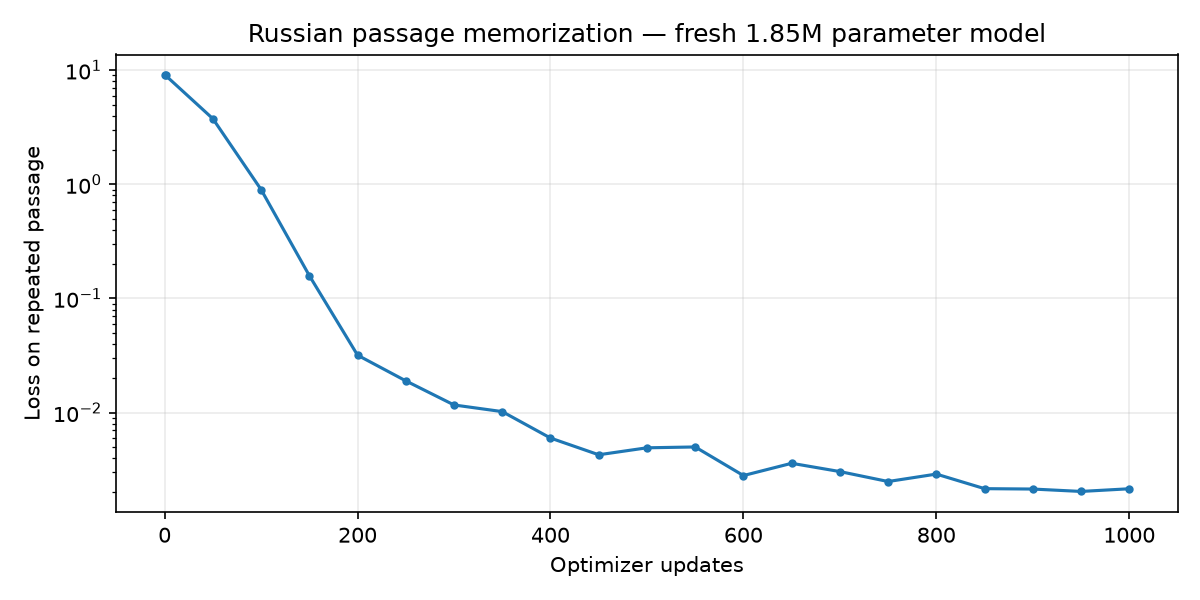

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([m['step'] for m in metrics], [m['memorization_loss'] for m in metrics], marker='.')
ax.set(xlabel='Optimizer updates', ylabel='Loss on repeated passage', yscale='log',
       title='Russian passage memorization — fresh 1.85M parameter model')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(run_dir / 'loss.png', dpi=150)
plt.show()

## Result

The second run passes: passage loss falls from 9.01888 to 0.002150 in 1,000 updates (21.2 seconds on this machine). All three 64-token continuations match exactly, with both greedy decoding and temperature 0.2. Teacher-forced accuracy is 99.375–100%; checkpoint reload changes logits by exactly zero.

This confirms that the fresh model and current compiled training, accumulation, tokenizer, checkpoint, and generation paths can memorize real Russian text. It does not establish generalization to the web corpus. The first run also shows why prompt positions must be represented in this diagnostic.
